# AE-GRU

In [1]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

file_path = "/content/drive/MyDrive/Machine_Learning/Final_Project/energydata_reviewed.csv"
df = pd.read_csv(file_path)
df.head(2)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.7900,19.79,44.73,19.0,...,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.7225,19.79,44.79,19.0,...,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2


In [3]:
from sklearn.preprocessing import MinMaxScaler
df['date'] = pd.to_datetime(df['date'])
df['hour'] = df['date'].dt.hour
df['day_of_week'] = df['date'].dt.dayofweek

df.drop(columns=['date'], inplace=True)

scaler = MinMaxScaler()
feature_columns = df.columns.difference(['Appliances'])  # Exclude target

df[feature_columns] = scaler.fit_transform(df[feature_columns])
df[feature_columns].head(2)

,Press_mm_hg,RH_1,RH_2,RH_3,RH_4,RH_5,RH_6,RH_7,RH_8,RH_9,...,T7,T8,T9,T_out,Tdewpoint,Visibility,Windspeed,day_of_week,hour,lights
0,0.097674,0.566187,0.684038,0.746066,0.764262,0.381691,0.841827,0.653428,0.661412,0.677290,...,0.170594,0.173329,0.223032,0.372990,0.538462,0.953846,0.50000,0.0,0.73913,0.428571
1,0.100000,0.541326,0.682140,0.748871,0.782437,0.381691,0.839872,0.651064,0.660155,0.678532,...,0.170594,0.173329,0.226500,0.369239,0.533937,0.894872,0.47619,0.0,0.73913,0.428571


## Prepare data for GRU autoencoder

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split

time_steps = 24

def create_sequences(data, target_column, time_steps):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data.iloc[i:i+time_steps].values)
        y.append(data.iloc[i+time_steps][target_column])
    return np.array(X), np.array(y)

target_column = 'Appliances'
X, y = create_sequences(df, target_column, time_steps)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((15768, 24, 28), (3943, 24, 28), (15768,), (3943,))

# Build & Train the GRU Autoencoder

Epoch 1/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - loss: 349.3610 - val_loss: 181.5706
Epoch 2/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - loss: 241.5866 - val_loss: 181.6806
Epoch 3/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - loss: 246.8491 - val_loss: 179.7923
Epoch 4/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - loss: 225.2377 - val_loss: 164.0892
Epoch 5/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - loss: 218.2946 - val_loss: 155.9522
Epoch 6/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - loss: 206.1902 - val_loss: 146.1008
Epoch 7/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - loss: 198.0649 - val_loss: 153.9173
Epoch 8/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - loss: 179.2957 - val_loss: 122.3826
Epoch 9/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - loss: 172.7117 - val_loss: 161.2331
Epoch 10/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - loss: 195.5844 - val_loss: 134.6313
Epoch 11/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - loss: 168.9120 - val_l

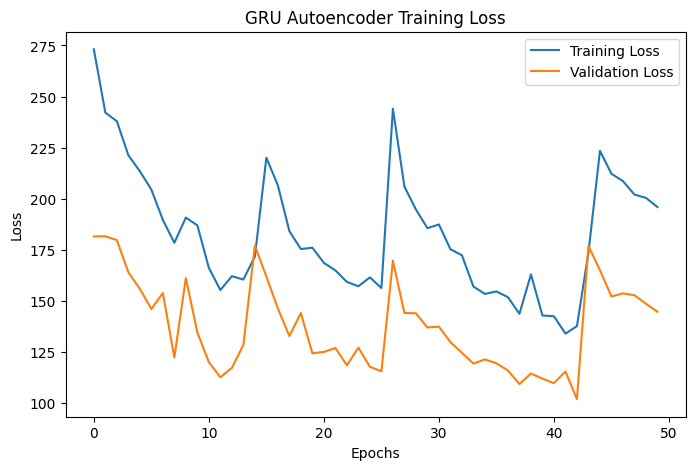

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GRU, RepeatVector, TimeDistributed, Dense
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Define GRU Autoencoder Model
input_layer = Input(shape=(time_steps, X_train.shape[2]))

# Encoder
encoded = GRU(64, activation='relu', return_sequences=False)(input_layer)

# Latent Space
latent = Dense(16, activation='relu')(encoded)

# Decoder
decoded = RepeatVector(time_steps)(latent)
decoded = GRU(64, activation='relu', return_sequences=True)(decoded)
output_layer = TimeDistributed(Dense(X_train.shape[2]))(decoded)

# Compile Model
autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss='mse')

# Train Model
history = autoencoder.fit(
    X_train, X_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, X_test),
    verbose=1
)

# Plot the behavior
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('GRU Autoencoder Training Loss')
plt.legend()
plt.show()

In [6]:
# Extracting the features from the AE and reshaping to fit GRU input format (batch_size, time_steps, features)

encoder = Model(inputs=input_layer, outputs=latent)
X_train_encoded = encoder.predict(X_train)
X_test_encoded = encoder.predict(X_test)

X_train_encoded = X_train_encoded.reshape(X_train_encoded.shape[0], 1, X_train_encoded.shape[1])
X_test_encoded = X_test_encoded.reshape(X_test_encoded.shape[0], 1, X_test_encoded.shape[1])

X_train_encoded.shape, X_test_encoded.shape

493/493 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


((15768, 1, 16), (3943, 1, 16))

## Single step forecasting

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

# Define GRU Forecasting Model
single_step_model = Sequential([
    GRU(64, activation='relu', return_sequences=False, input_shape=(1, X_train_encoded.shape[2])),
    Dense(32, activation='relu'),
    Dense(1)
])

# Compile Model
single_step_model.compile(optimizer='adam', loss='mse')
single_step_model.fit(X_train_encoded, y_train, epochs=50, batch_size=16, validation_data=(X_test_encoded, y_test), verbose=1)
y_pred_single = single_step_model.predict(X_test_encoded)


Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


986/986 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 8032.8574 - val_loss: 4858.2852
Epoch 2/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 6149.0742 - val_loss: 4463.3208
Epoch 3/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 5675.2739 - val_loss: 4401.4399
Epoch 4/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 5674.0879 - val_loss: 4392.5137
Epoch 5/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5779.9102 - val_loss: 4339.7202
Epoch 6/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5899.3872 - val_loss: 4463.9082
Epoch 7/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 5551.3818 - val_loss: 4337.7979
Epoch 8/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 5329.7402 - val_loss: 4705.5347
Epoch 9/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 5456.6997 - val_loss: 4220.2075
Epoch 10/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 5280.6694 - val_loss: 4274.7886
Epoch 11/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 5181.8765 - val_loss: 4091.19

Single-Step Forecasting Performance:
RMSE: 63.02884745664692, MSE: 3972.635611713267, MAE: 27.257345609788267, R² Score: 0.5150169662869513


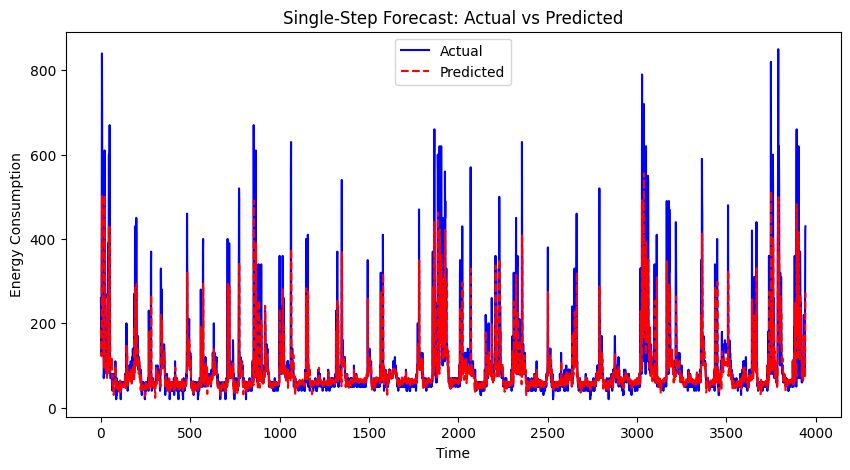

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np


rmse_single = np.sqrt(mean_squared_error(y_test, y_pred_single))
mse_single = mean_squared_error(y_test, y_pred_single)
mae_single = mean_absolute_error(y_test, y_pred_single)
r2_single = r2_score(y_test, y_pred_single)

print(f"Single-Step Forecasting Performance:")
print(f"RMSE: {rmse_single}, MSE: {mse_single}, MAE: {mae_single}, R² Score: {r2_single}")

plt.figure(figsize=(10, 5))
plt.plot(y_test, label='Actual', color='blue')
plt.plot(y_pred_single, label='Predicted', color='red', linestyle='dashed')
plt.xlabel('Time')
plt.ylabel('Energy Consumption')
plt.title('Single-Step Forecast: Actual vs Predicted')
plt.legend()
plt.show()


## Multi step forecasting (1 hour forward)

In [9]:
future_steps = 6  # Forecast next 6 time steps

def create_multistep_sequences(data, target_column, time_steps, future_steps):
    X, y = [], []
    for i in range(len(data) - time_steps - future_steps):
        X.append(data.iloc[i:i+time_steps].values)
        y.append(data.iloc[i+time_steps:i+time_steps+future_steps][target_column].values)
    return np.array(X), np.array(y)

# Generate multi-step sequences
X_multi, y_multi = create_multistep_sequences(df, 'Appliances', time_steps, future_steps)

# Train-Test Split
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(X_multi, y_multi, test_size=0.2, shuffle=False)

In [10]:
# Multi-Step Forecasting Model
multi_step_model = Sequential([
    GRU(64, activation='relu', return_sequences=True, input_shape=(time_steps, X_train_multi.shape[2])),
    GRU(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(future_steps)  # Output multiple future steps
])

# Compile Model
multi_step_model.compile(optimizer='adam', loss='mse')

# Train Model
multi_step_model.fit(X_train_multi, y_train_multi, epochs=50, batch_size=16, validation_data=(X_test_multi, y_test_multi), verbose=1)

# Predict future values
y_pred_multi = multi_step_model.predict(X_test_multi)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 33s 29ms/step - loss: 9939.4893 - val_loss: 5950.4590
Epoch 2/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - loss: 7842.9399 - val_loss: 6423.9497
Epoch 3/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - loss: 8209.4639 - val_loss: 5787.7734
Epoch 4/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - loss: 8132.5859 - val_loss: 5844.1602
Epoch 5/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - loss: 7669.7896 - val_loss: 5766.9458
Epoch 6/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 42s 29ms/step - loss: 7489.0518 - val_loss: 5915.3936
Epoch 7/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - loss: 7876.0991 - val_loss: 5822.3135
Epoch 8/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 40s 28ms/step - loss: 7702.1816 - val_loss: 5719.5479
Epoch 9/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - loss: 7711.3838 - val_loss: 5580.0806
Epoch 10/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - loss: 7808.6553 - val_loss: 5653.3203
Epoch 11/50
986/986 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - lo


Multi-Step Forecasting Performance:
RMSE: 76.54636947424417, MSE: 5859.3466796875, MAE: 39.992374420166016, R² Score: 0.2834012508392334


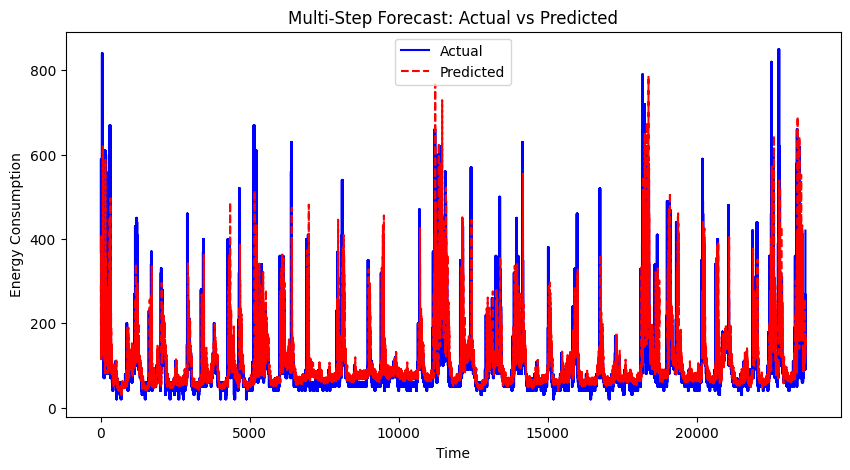

In [11]:
rmse_multi = np.sqrt(mean_squared_error(y_test_multi.flatten(), y_pred_multi.flatten()))
mse_multi = mean_squared_error(y_test_multi.flatten(), y_pred_multi.flatten())
mae_multi = mean_absolute_error(y_test_multi.flatten(), y_pred_multi.flatten())
r2_multi = r2_score(y_test_multi.flatten(), y_pred_multi.flatten())

print(f"\nMulti-Step Forecasting Performance:")
print(f"RMSE: {rmse_multi}, MSE: {mse_multi}, MAE: {mae_multi}, R² Score: {r2_multi}")

plt.figure(figsize=(10, 5))
plt.plot(y_test_multi.flatten(), label='Actual', color='blue')
plt.plot(y_pred_multi.flatten(), label='Predicted', color='red', linestyle='dashed')
plt.xlabel('Time')
plt.ylabel('Energy Consumption')
plt.title('Multi-Step Forecast: Actual vs Predicted')
plt.legend()
plt.show()

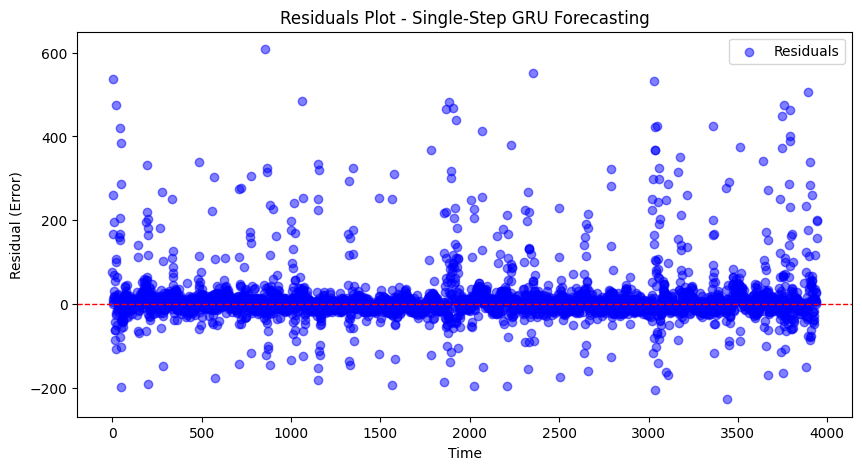

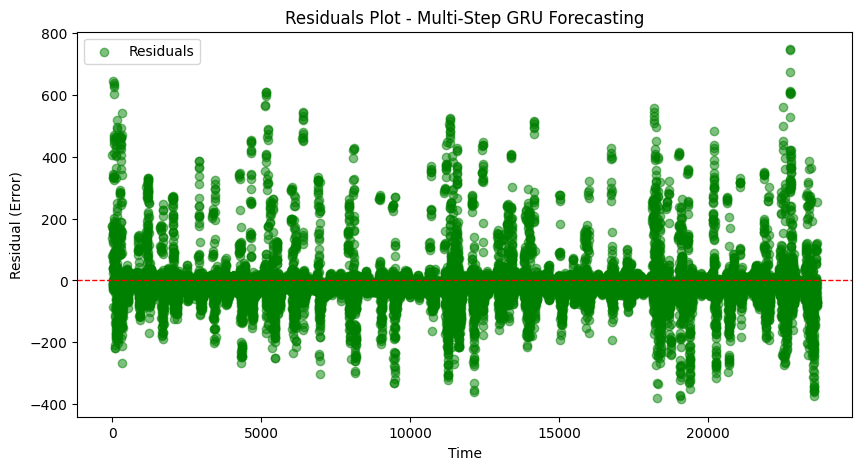

In [12]:
import matplotlib.pyplot as plt

residuals_single = y_test - y_pred_single.flatten()
residuals_multi = y_test_multi.flatten() - y_pred_multi.flatten()

# Single
plt.figure(figsize=(10, 5))
plt.scatter(range(len(residuals_single)), residuals_single, color='blue', alpha=0.5, label='Residuals')
plt.axhline(y=0, color='red', linestyle='dashed', linewidth=1)
plt.xlabel('Time')
plt.ylabel('Residual (Error)')
plt.title('Residuals Plot - Single-Step GRU Forecasting')
plt.legend()
plt.show()

# Multi
plt.figure(figsize=(10, 5))
plt.scatter(range(len(residuals_multi)), residuals_multi, color='green', alpha=0.5, label='Residuals')
plt.axhline(y=0, color='red', linestyle='dashed', linewidth=1)
plt.xlabel('Time')
plt.ylabel('Residual (Error)')
plt.title('Residuals Plot - Multi-Step GRU Forecasting')
plt.legend()
plt.show()